In [148]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve


def osc_kernel(fs, freq_hz, tau_ms, amp=1.0, n_tau=6):
    tau_s = tau_ms / 1000
    kt = np.arange(0, n_tau * tau_s + 1 / fs, 1 / fs)
    h = np.exp(-kt / tau_s) * np.cos(2 * np.pi * freq_hz * kt)
    h *= amp / np.max(np.abs(h))
    return h


def apply_kernel(stim_times, fs, dur, freq_hz, tau_ms, amp=1.0):
    t = np.arange(0, dur, 1 / fs)
    stim_idx = np.round(np.asarray(stim_times) * fs).astype(int)
    stim_idx = stim_idx[(stim_idx >= 0) & (stim_idx < len(t))]
    impulses = np.zeros_like(t)
    impulses[stim_idx] = 1.0
    h = osc_kernel(fs, freq_hz, tau_ms, amp=amp)
    x = fftconvolve(impulses, h, mode='full')[: len(t)]
    return t, x, stim_idx, h


def morlet_phase(x, fs, f0, n_cycles=5):
    sigma_t = n_cycles / (2 * np.pi * f0)
    wt = np.arange(-4 * sigma_t, 4 * sigma_t + 1 / fs, 1 / fs)
    psi = np.exp(2j * np.pi * f0 * wt) * np.exp(-0.5 * (wt / sigma_t) ** 2)
    psi /= np.sqrt(np.sum(np.abs(psi) ** 2))
    return np.angle(fftconvolve(x, np.conj(psi[::-1]), mode='same'))

In [149]:
rng = np.random.default_rng()

def gen_stim_times(f0, dur, jitter_sd, t0=0, t1=0):
    end = dur - t1
    tt = []
    current = t0
    while current < end:
        isi = rng.normal(1 / f0, jitter_sd)
        if isi <= 0:
            continue
        current += isi
        if current <= end:
            tt.append(current)
    return np.array(tt)

#gen_stim_times(10, 1, 0.01, 0.2, 0.2)

def gen_signal(dur, fs, tt_stim, ker_amp, ker_f, ker_tau, noise_sd=0):
    t, x, _, h = apply_kernel(tt_stim, fs, dur, ker_f, ker_tau, ker_amp)
    if noise_sd > 0:
        x = x + rng.normal(0, noise_sd, size=x.shape)
    return t, x, tt_stim, h

#t, x, tt_stim, h = gen_signal(f0=10, fs=1000, dur=1, jit_sd=0.03,
#                        ker_amp=1, ker_f=60, ker_tau=10, noise_sd=0.05)
#plt.figure(figsize=(10, 4))
#plt.plot(t, x); plt.show()

def signal_itc(x, tt_stim, fs, f0, n_cycles=5):
    phase = morlet_phase(x, fs, f0, n_cycles=n_cycles)
    sigma_t = n_cycles / (2 * np.pi * f0)
    edge = int(np.ceil(4 * sigma_t * fs))
    stim_idx = np.round(tt_stim * fs).astype(int)
    valid = stim_idx[(stim_idx >= edge) & (stim_idx < len(x) - edge)]
    phasors = np.exp(1j * phase[valid])
    itc = np.abs(np.mean(phasors))
    return itc, phasors


In [150]:
def itc_curve(fs, dur, f0, freq_hz, layer, jitter_sds, n_trials=50, noise_sd=0.0, seed=1):
    rng = np.random.default_rng(seed)
    rows = []

    for jitter_sd in jitter_sds:
        all_phasors = []
        seed_ = int(rng.integers(0, 2**32 - 1))
        trial_onsets = jittered_onsets(f0, dur, jitter_sd, n_trials, seed=seed_)
        for onsets in trial_onsets:
            _, x, stim_idx, _ = generate_signal(
                onsets, fs, dur, freq_hz, layer, noise_sd=noise_sd, rng=rng)
            _, phasors = signal_itc(x, stim_idx, fs, f0)
            all_phasors.append(phasors)
        all_phasors = np.concatenate(all_phasors)
        rows.append(np.abs(np.mean(all_phasors)))


In [151]:
fs = 1000
dur = 500
f0 = 10

ker_f = 10
noise_sd = 0.4

jitter_sds = np.linspace(0, 1, 40) / f0

layers = {
    'layer_1': {'amp': 1, 'ker_tau': 25},
    'layer_2': {'amp': 1, 'ker_tau': 50}
}

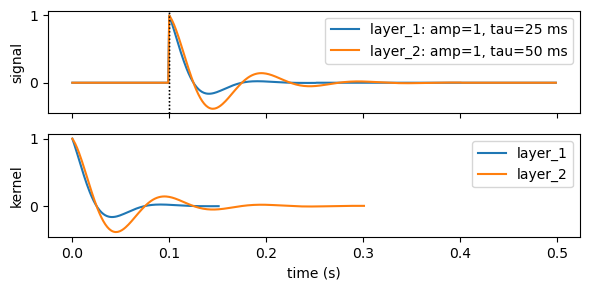

In [152]:
# Kernel application check: one stimulus, no noise
single_stim = [0.1]
T = 0.5
kernel_data = {}
for name, layer in layers.items():
    kernel_data[name] = apply_kernel(
        single_stim, fs, T, ker_f,
        layer['ker_tau'], layer['amp']
    )

fig, axes = plt.subplots(2, 1, figsize=(6, 3), sharex=True)
for name, (t, x, stim_idx, _) in kernel_data.items():
    axes[0].plot(t, x, label=f"{name}: amp={layers[name]['amp']}, tau={layers[name]['ker_tau']} ms")
    axes[0].axvline(t[stim_idx[0]], color='k', linestyle=':', linewidth=1)
axes[0].set_ylabel('signal')
axes[0].legend()

for name, (_, _, _, h) in kernel_data.items():
    kt = np.arange(len(h)) / fs
    axes[1].plot(kt, h, label=name)
axes[1].set_xlabel('time (s)')
axes[1].set_ylabel('kernel')
axes[1].legend()
plt.tight_layout()

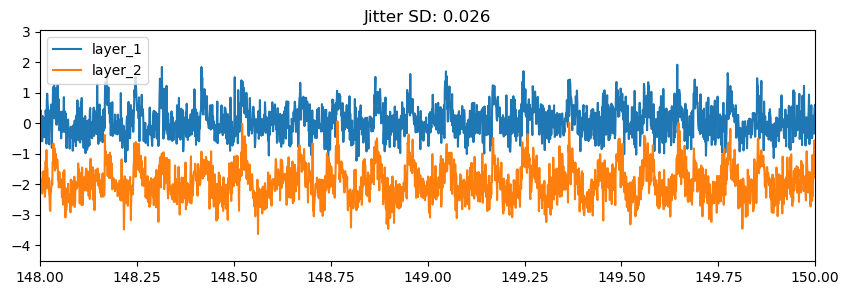

In [153]:
# Generate signals
signals = {}
for n, jit_sd in enumerate(jitter_sds):
    tt_stim = gen_stim_times(f0, dur, jit_sd)
    for l, layer in enumerate(layers.values()):
        t, x, tt_stim, _ = gen_signal(
            dur, fs, tt_stim, layer['amp'], ker_f, layer['ker_tau'], noise_sd)
        signals[(n, l)] = {'t': t, 'x': x, 'tt_stim': tt_stim}
        
plt.figure(figsize=(10, 3))
jit_n = 10
for l, name in enumerate(layers.keys()):
    sig = signals[(jit_n, l)]
    plt.plot(sig['t'], sig['x'] - l * 2, label=name)
plt.title(f'Jitter SD: {jitter_sds[jit_n]:.3f}')
plt.xlim(148, 150)
plt.legend()
plt.show()

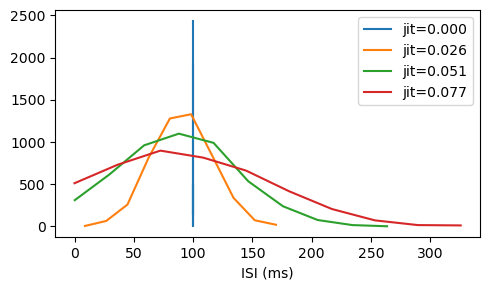

In [154]:
plt.figure(figsize=(5, 3))
for jit_n in [0, 10, 20, 30]:
    tt_stim = signals[(jit_n, 0)]['tt_stim']
    isi = np.diff(tt_stim) * 1000
    h, b = np.histogram(isi, bins=10)
    plt.plot(b[:-1], h, label=f'jit={jitter_sds[jit_n]:.3f}')
plt.xlabel('ISI (ms)')
plt.legend()
plt.tight_layout()
plt.show()

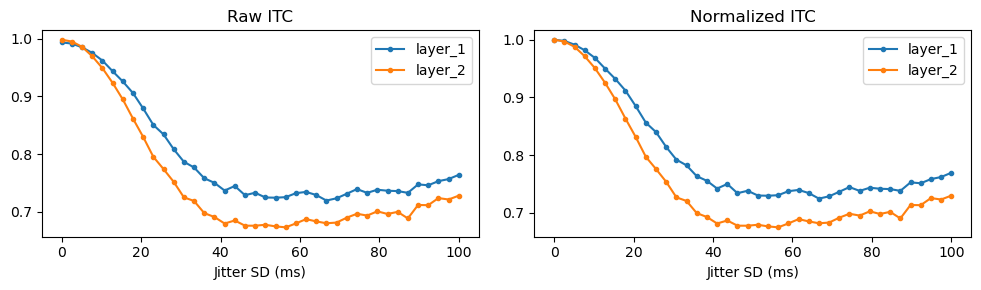

In [155]:
# ITC vs jitter for the existing simulated signals
itc_curves = {name: [] for name in layers.keys()}
for n, _ in enumerate(jitter_sds):
    for l, name in enumerate(layers.keys()):
        sig = signals[(n, l)]
        itc, _ = signal_itc(sig['x'], sig['tt_stim'], fs, f0)
        itc_curves[name].append(itc)

for name in layers.keys():
    itc_curves[name] = np.array(itc_curves[name])

# Normalized ITC
itc_norm = {name: vals / vals.max() for name, vals in itc_curves.items()}

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=True, sharey=False)

# ITC vs jitter
for name in layers.keys():
    axes[0].plot(jitter_sds * 1000, itc_curves[name], marker='o', ms=3, label=name)
axes[0].set_title('Raw ITC')
axes[0].set_xlabel('Jitter SD (ms)')
#axes[0].set_ylim(0, 1)
axes[0].legend()

# ITC (normalized) vs jitter
for name in layers.keys():
    axes[1].plot(jitter_sds * 1000, itc_norm[name], marker='o', ms=3, label=name)
axes[1].set_title('Normalized ITC')
axes[1].set_xlabel('Jitter SD (ms)')
#axes[1].set_ylim(0, 1.05)
axes[1].legend()

plt.tight_layout()
plt.show()